In [1]:
'''
libs extenas
!pip install ruptures
'''
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import shapiro
from scipy import stats
from statsmodels.tsa.seasonal import STL
import statsmodels.api as sm
from classes.metrics.hurst import Hurst
ehc = pd.read_excel("data/Dados Demanda Ciclo Otto 8-3009.xlsx")
ehc['Unnamed: 0'] = pd.to_datetime(ehc['Unnamed: 0'])
ehc = ehc[['Unnamed: 0', 'Demanda Etanol Hidratado (m3)']].rename(columns={'Unnamed: 0': 'Data'})
ehc.set_index('Data', inplace=True)

/home/arick/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-z8g9w4hw because there was an issue with the default path (/home/arick/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


/tmp/ipykernel_46/586811599.py:17: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ehc.set_index('Data', inplace=True)


## [sem nome]

Premissas

1. Sazonalidade da demanda do etanol não é bem marcada por ciclos fisicos e economicos, considerando uma propriedade da frequencia/dominio. 

## Diagnostico da serie 

### Hurst Coefficient: 

busca identificar se a serie possui comportamento persistente ou reversão a média

<Axes: >

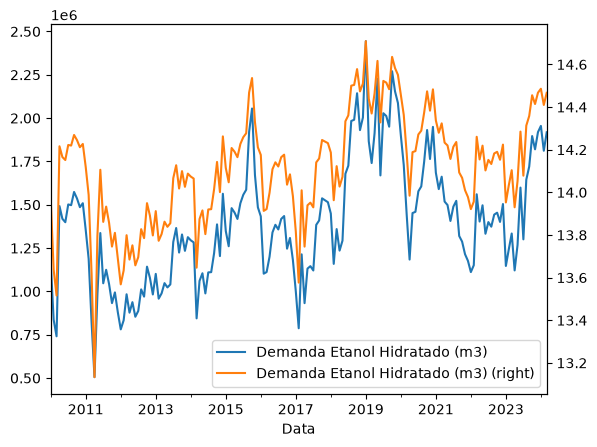

In [2]:
ax = ehc.plot()
np.log(ehc).plot(ax=ax, secondary_y=True)

Primeiro, encontramos o ciclo de sazonalidade

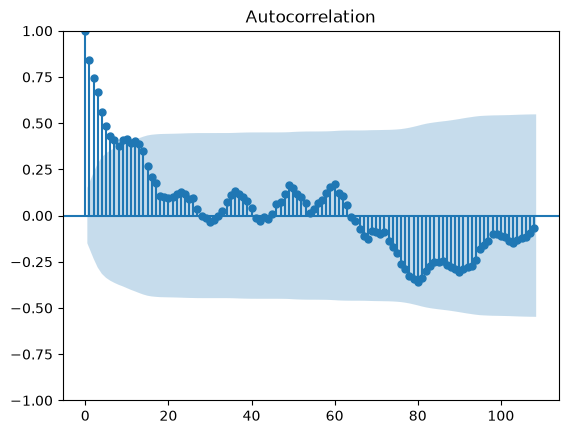

In [3]:
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(ehc['Demanda Etanol Hidratado (m3)'].dropna(), lags=108)
plt.show()

fazemos a decomposição da sazonalidade, para calcular o coeficiente.

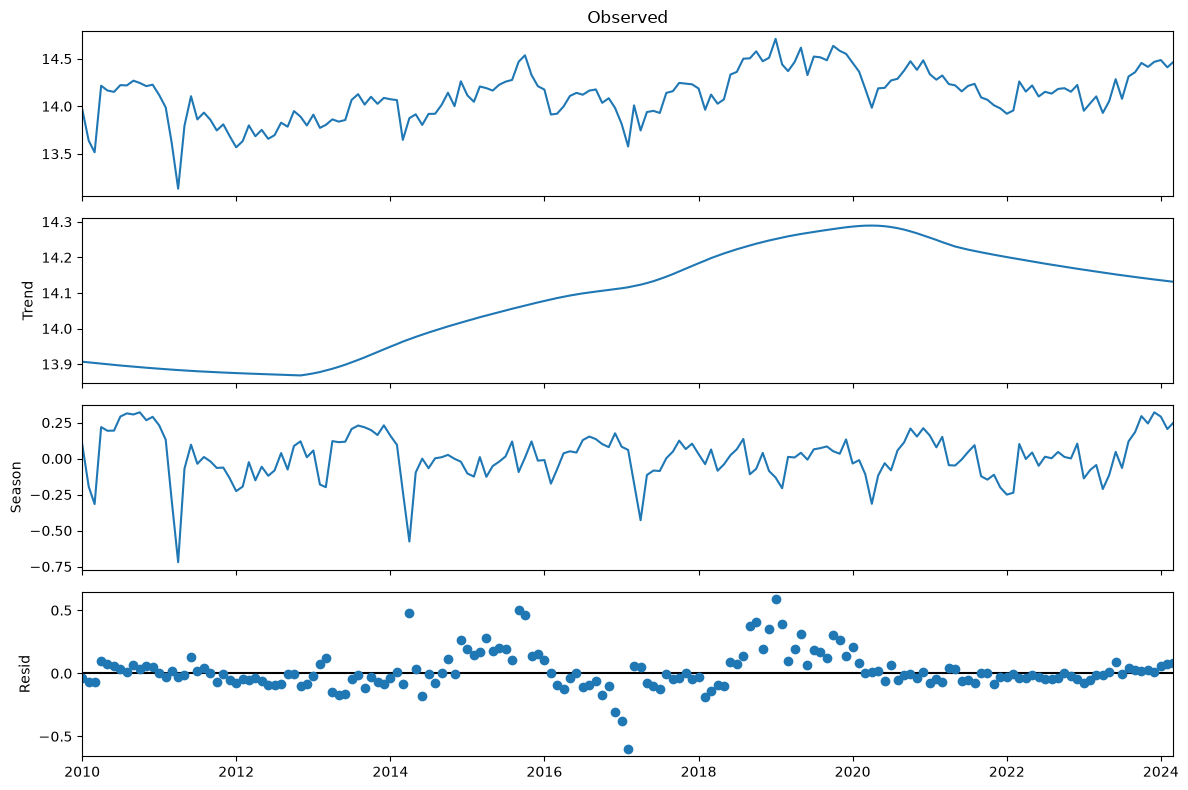

In [4]:
stl = STL(np.log(ehc), period=36, robust=True)
resultado = stl.fit()
fig = resultado.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

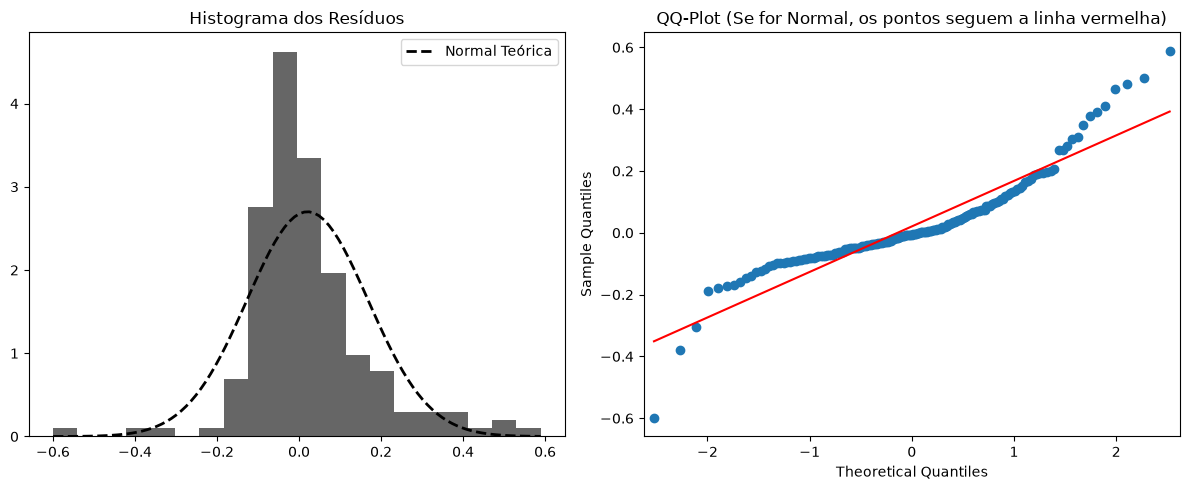

In [5]:
residuos = resultado.resid.dropna()

# Plotando a comparação com a Normal
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# 1. Histograma com a curva da Normal sobreposta
ax[0].hist(residuos, bins=20, density=True, alpha=0.6, color='black')
x = np.linspace(residuos.min(), residuos.max(), 100)
ax[0].plot(x, stats.norm.pdf(x, residuos.mean(), residuos.std()), 'k--', lw=2, label='Normal Teórica')
ax[0].set_title('Histograma dos Resíduos')
ax[0].legend()

# 2. QQ-Plot (A forma mais precisa de validar normalidade)
sm.qqplot(residuos, line='s', ax=ax[1])
ax[1].set_title('QQ-Plot (Se for Normal, os pontos seguem a linha vermelha)')
plt.tight_layout()
plt.show()

### Encontrando o melhor periodo de sazonalidade

Fazemos uma iteração de [2,36] para identificar qual decomposição possui os residuos mais proximos a uma distribuição normal. Utilizamos um teste de normalidade formal, como o Teste de **Shapiro-Wilk**.

In [6]:
serie_log = np.log(ehc['Demanda Etanol Hidratado (m3)'].dropna())
melhor_periodo = None
melhor_stat = 0

for p in range(2, 37):
    try:
        stl = STL(serie_log, period=p, robust=True)
        resultado = stl.fit()
        residuos = resultado.resid.dropna()
        stat, p_valor = shapiro(residuos)
        
        # Atualiza se a distribuição atual for mais próxima da normal
        if stat > melhor_stat:
            melhor_stat = stat
            melhor_periodo = p
            
    except ValueError:
        # Pula caso o período seja maior que a quantidade de dados disponíveis
        continue

print(f"Melhor 'period' encontrado: {melhor_periodo}")
print(f"Estatística de Shapiro-Wilk (W): {melhor_stat:.4f} (mais próximo de 1 = mais normal)")

Melhor 'period' encontrado: 32
Estatística de Shapiro-Wilk (W): 0.9587 (mais próximo de 1 = mais normal)


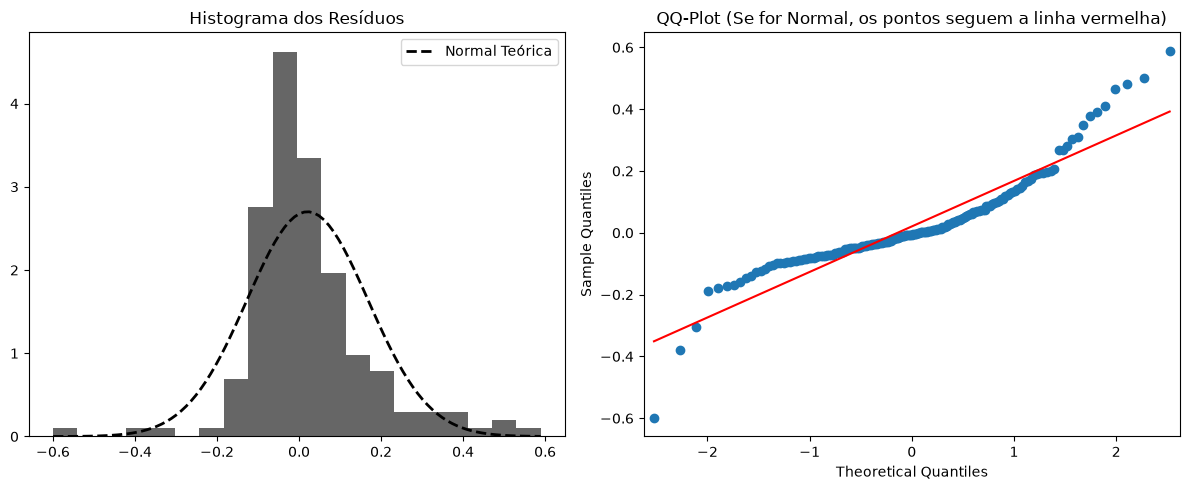

In [7]:
residuos = resultado.resid.dropna()

# Plotando a comparação com a Normal
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# 1. Histograma com a curva da Normal sobreposta
ax[0].hist(residuos, bins=20, density=True, alpha=0.6, color='black')
x = np.linspace(residuos.min(), residuos.max(), 100)
ax[0].plot(x, stats.norm.pdf(x, residuos.mean(), residuos.std()), 'k--', lw=2, label='Normal Teórica')
ax[0].set_title('Histograma dos Resíduos')
ax[0].legend()

# 2. QQ-Plot (A forma mais precisa de validar normalidade)
sm.qqplot(residuos, line='s', ax=ax[1])
ax[1].set_title('QQ-Plot (Se for Normal, os pontos seguem a linha vermelha)')
plt.tight_layout()
plt.show()

In [8]:
stl = STL(np.log(ehc), period=32, robust=True)
resultado = stl.fit()

In [9]:
serie_dessazonalizada = np.log(ehc)['Demanda Etanol Hidratado (m3)'] - resultado.seasonal

In [10]:
hurst = Hurst(q=2, min_t=3, max_t=13)
valor_h, regime = hurst.calculate(serie_dessazonalizada)
print(f"Hurst sem sazonalidade: {valor_h:.4f} | Regime: {regime}")

Hurst sem sazonalidade: 0.1932 | Regime: Anti-persistente


## Deslocamento na média 01: Algoritmo PELT

Já identificamos que a serie possui um forte comportamento anti-persistente. Agora buscaremos saber se houve deslocamento na média.

Índices onde houve deslocamento de média: [55]


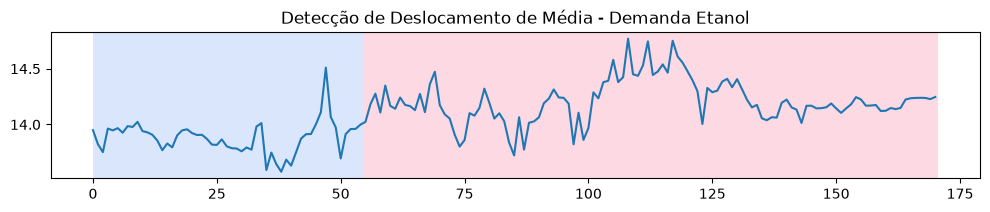

In [11]:
import ruptures as rpt

sinal = serie_dessazonalizada.values if hasattr(serie_dessazonalizada, 'values') else serie_dessazonalizada

# Detecta mudanças de média (modelo 'l2' busca quebras na média)
algo = rpt.Pelt(model="l2").fit(sinal)
pontos_quebra = algo.predict(pen=3) # 'pen' controla a sensibilidade (quanto maior, menos quebras detecta)

print("Índices onde houve deslocamento de média:", pontos_quebra[:-1])

# Plota a série com as quebras detectadas
rpt.display(sinal, pontos_quebra)
plt.title("Detecção de Deslocamento de Média - Demanda Etanol")
plt.show()

## Deslocamento na média 02: Regressão na média de cada ano

Regressão linear ajustada sobre as médias anuais (linha verde tracejada mostrando a direção geral de longo prazo)

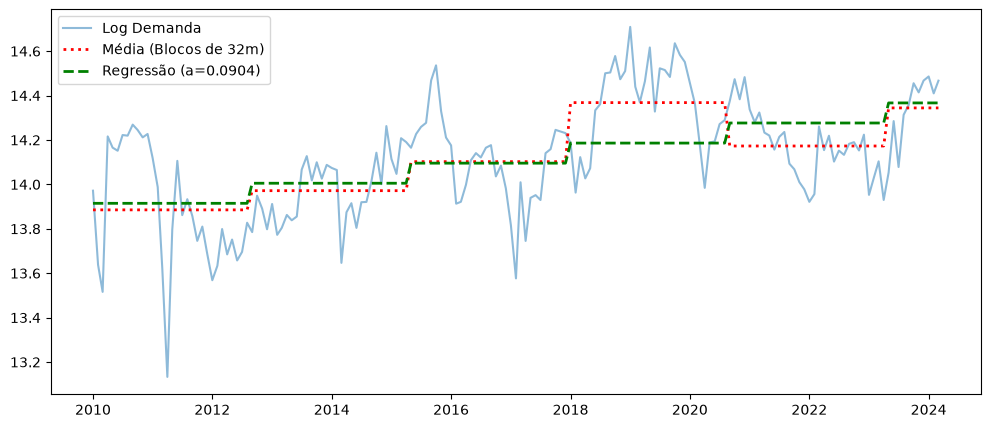

In [12]:
ehc['log_demanda'] = np.log(ehc['Demanda Etanol Hidratado (m3)'])

ehc['ciclo_32m'] = np.arange(len(ehc)) // 32
ehc['media_ciclo'] = ehc.groupby('ciclo_32m')['log_demanda'].transform('mean')

medias = ehc.groupby('ciclo_32m')['log_demanda'].mean()
a, b = np.polyfit(medias.index, medias.values, 1)
ehc['regressao'] = a * ehc['ciclo_32m'] + b

plt.figure(figsize=(12, 5))
plt.plot(ehc.index, ehc['log_demanda'], label='Log Demanda', alpha=0.5)
plt.plot(ehc.index, ehc['media_ciclo'], 'r:', linewidth=2, label='Média (Blocos de 32m)')
plt.plot(ehc.index, ehc['regressao'], 'g--', linewidth=2, label=f'Regressão (a={a:.4f})')
plt.legend()
plt.show()

## Conclusão: 

**Série Anti-Persistente / demanda de etanol com H = 0,2**

• O que a rede precisa fazer: **Capturar oscilações curto prazo** e reversão à média  

• Arquiteturas indicadas: Modelos focados em padrões locais como N-BEATS, N-HiTS ou redes lineares modernas como DLinear / PatchTST. Evvitar LSTMs, profundas costumam sofrer overfitting (decoram o ruído) nesse cenário.  

• Tamanho da janela (Lookback): Curtas (ex: 6 a x passos). Como a série reverte rápido, olhar muito para trás só adiciona ruído ao treinamento.  

• Pré-processamento crítico: Para reversão na média usar **RevIN** 

## Usando o PELT para detectar *Changepoints* (nível, distribuição e tendência)

O algoritmo **PELT** (*Pruned Exact Linear Time*) é um detector geral de ***changepoints*** (pontos de mudança estrutural).  
O que ele detecta depende do parâmetro `model`:

- **`model="l2"`**: detecta mudanças de **média/nível** (série constante por partes).
- **`model="rbf"`**: detecta mudanças de **distribuição** (média e/ou variância, sem assumir linearidade).
- **`model="linear"`**: detecta mudanças de **inclinação/tendência** (regressão linear por partes).

**Parâmetros principais:**
- `min_size`: tamanho mínimo de cada segmento/regime (ex.: `12` meses).
- `jump`: passo de busca (`jump=1` avalia todo ponto; o padrão `5` acelera, mas arredonda o índice para múltiplos de 5).
- `pen`: penalidade por cada quebra adicionada (quanto **maior**, **menos** *changepoints* são detectados).

> **Observação:** `algo.predict(pen=...)` sempre devolve o tamanho total `len(sinal)` como último elemento; os *changepoints* reais são `pontos[:-1]`.

PELT (model='l2') — Mudança de média/nível: índices=[26, 57, 101, 135] | datas=['2012-03', '2014-10', '2018-06', '2021-04']
PELT (model='rbf') — Mudança de distribuição: índices=[42, 101, 133] | datas=['2013-07', '2018-06', '2021-02']
PELT (model='linear') — Mudança de tendência/inclinação: índices=[32, 71, 103, 139] | datas=['2012-09', '2015-12', '2018-08', '2021-08']


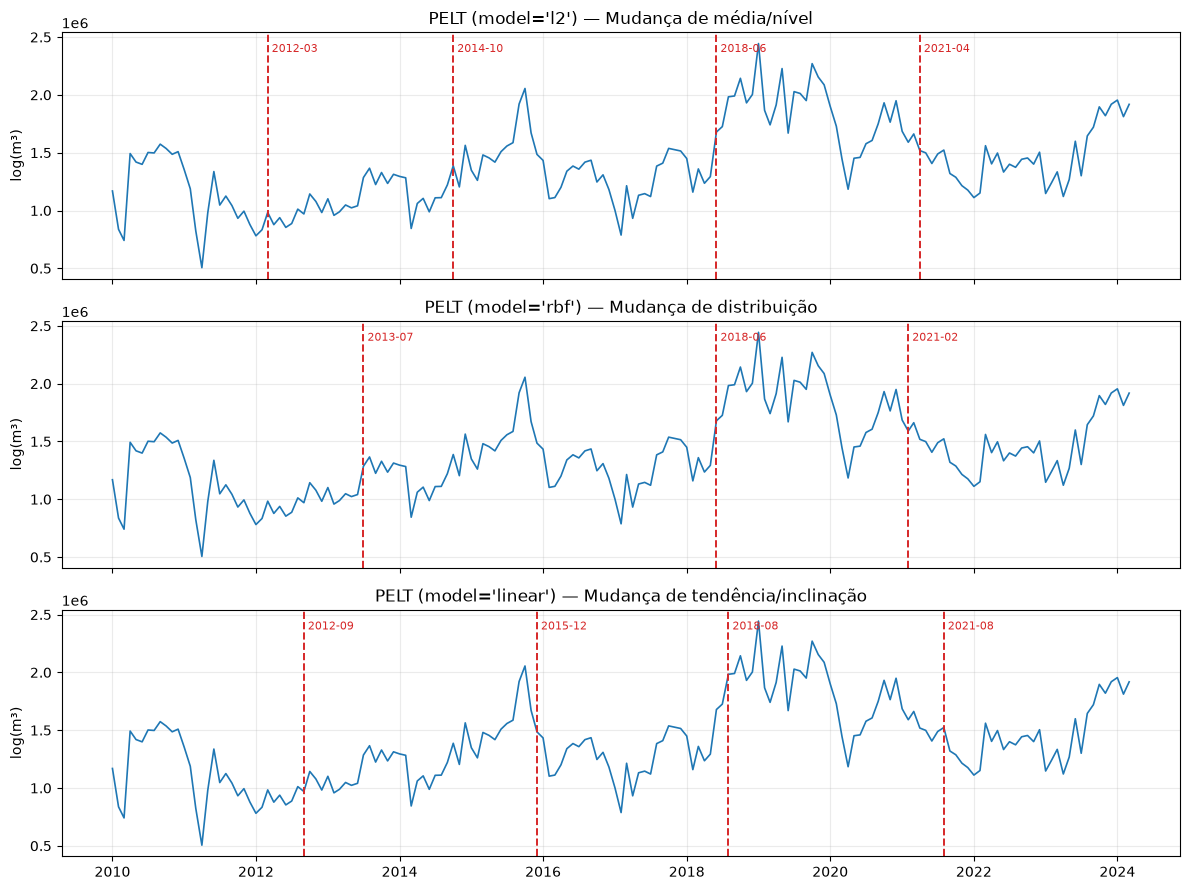

In [13]:
import ruptures as rpt

y = ehc['Demanda Etanol Hidratado (m3)'].values
datas = ehc.index
n = len(y)
t = np.arange(n, dtype=float)

# 1) Mudança de média/nível (l2)
cps_l2 = rpt.Pelt(model="l2", min_size=26, jump=1).fit(y).predict(pen=1.5)

# 2) Mudança de distribuição: média e/ou variância (rbf)
cps_rbf = rpt.Pelt(model="rbf", min_size=26, jump=1).fit(y).predict(pen=3.0)

# 3) Mudança de tendência/inclinação (linear)
# O ruptures espera uma matriz 2D: [alvo y, covariável t, constante 1]
X_lin = np.column_stack([y, t / n, np.ones(n)])
cps_lin = rpt.Pelt(model="linear", min_size=32, jump=1).fit(X_lin).predict(pen=0.5)

modelos = [
    ("PELT (model='l2') — Mudança de média/nível", cps_l2),
    ("PELT (model='rbf') — Mudança de distribuição", cps_rbf),
    ("PELT (model='linear') — Mudança de tendência/inclinação", cps_lin),
]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (titulo, cps) in zip(axes, modelos):
    quebras = cps[:-1]
    datas_cp = [datas[i].strftime('%Y-%m') for i in quebras]
    print(f"{titulo}: índices={quebras} | datas={datas_cp}")

    ax.plot(datas, y, color='tab:blue', lw=1.2, label='log(Demanda)')
    for cp in quebras:
        ax.axvline(datas[cp], color='tab:red', ls='--', lw=1.4)
        ax.text(datas[cp], y.max(), f" {datas[cp].strftime('%Y-%m')}",
                color='tab:red', fontsize=8, va='top')
    ax.set_title(titulo)
    ax.set_ylabel('log(m³)')
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Aplicando os *changepoints* do PELT (`linear`) para extrair tendência por partes e projetar o futuro

Abaixo, ajustamos o PELT **apenas no conjunto de treino** (evitando *data leakage*), ajustamos uma reta dentro de cada regime detectado e projetamos a inclinação do **último regime** para o horizonte futuro `H`.  
O resíduo resultante (`log_demanda - tendencia_pelt`) fica contínuo dentro de cada regime, sem os degraus artificiais de blocos fixos.

Changepoints no treino: ['2013-07', '2018-08']


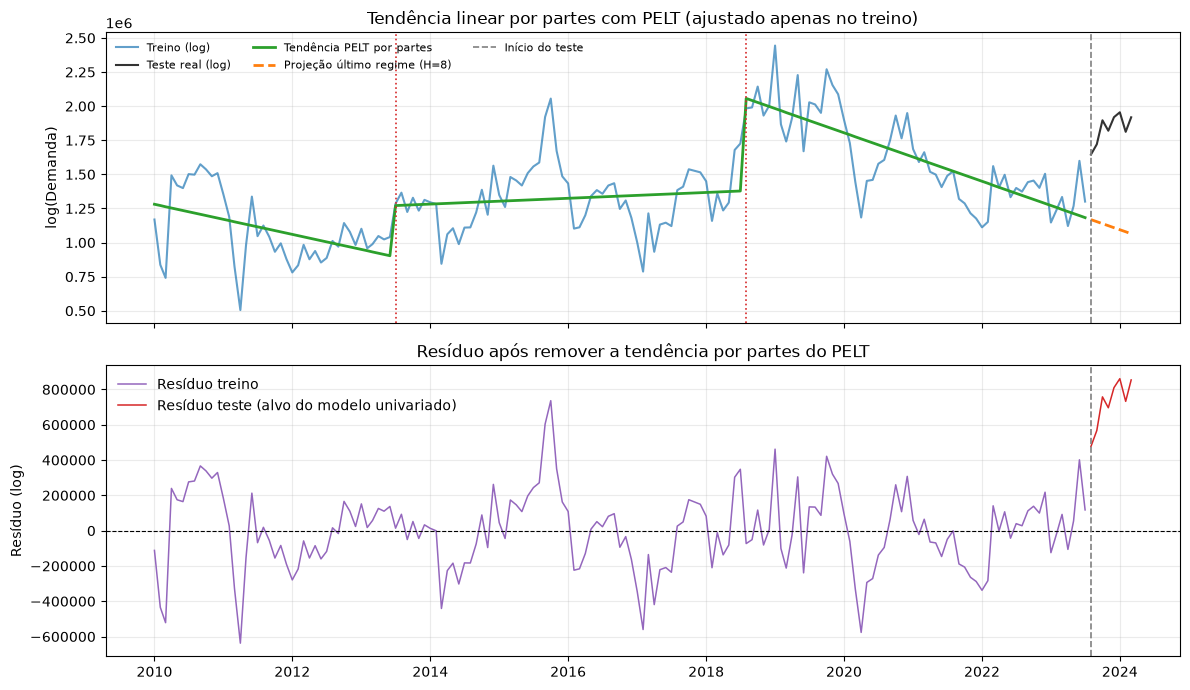

In [14]:
H = 8  # horizonte futuro (meses)
y_train = y[:-H]
y_test = y[-H:]
n_tr = len(y_train)
t_tr = np.arange(n_tr, dtype=float)

# 1) Detecta changepoints de tendência SOMENTE no treino
X_tr_lin = np.column_stack([y_train, t_tr / n_tr, np.ones(n_tr)])
cps_tr = rpt.Pelt(model="linear", min_size=42, jump=1).fit(X_tr_lin).predict(pen=0.5)
print("Changepoints no treino:", [datas[i].strftime('%Y-%m') for i in cps_tr[:-1]])

# 2) Ajusta uma regressão linear em cada segmento detectado
tendencia_tr = np.zeros(n_tr)
inicio = 0
for fim in cps_tr:
    t_seg = np.arange(inicio, fim, dtype=float)
    a_seg, b_seg = np.polyfit(t_seg, y_train[inicio:fim], 1)
    tendencia_tr[inicio:fim] = a_seg * t_seg + b_seg
    inicio = fim

# 3) Projeta o ÚLTIMO regime para o horizonte futuro H
t_fut = np.arange(n_tr, n_tr + H, dtype=float)
tendencia_fut = a_seg * t_fut + b_seg

# 4) Resíduo do treino (pronto para treinar o modelo univariado)
residuo_tr = y_train - tendencia_tr
residuo_test = y_test - tendencia_fut

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(datas[:n_tr], y_train, color='tab:blue', alpha=0.7, label='Treino (log)')
axes[0].plot(datas[n_tr:], y_test, color='black', alpha=0.8, label='Teste real (log)')
axes[0].plot(datas[:n_tr], tendencia_tr, color='tab:green', lw=2, label='Tendência PELT por partes')
axes[0].plot(datas[n_tr:], tendencia_fut, color='tab:orange', lw=2, ls='--', label=f'Projeção último regime (H={H})')
for cp in cps_tr[:-1]:
    axes[0].axvline(datas[cp], color='tab:red', ls=':', lw=1.2)
axes[0].axvline(datas[n_tr], color='gray', ls='--', lw=1.2, label='Início do teste')
axes[0].set_title('Tendência linear por partes com PELT (ajustado apenas no treino)')
axes[0].set_ylabel('log(Demanda)')
axes[0].legend(frameon=False, ncol=3, fontsize=8)
axes[0].grid(alpha=0.25)

axes[1].plot(datas[:n_tr], residuo_tr, color='tab:purple', lw=1.1, label='Resíduo treino')
axes[1].plot(datas[n_tr:], residuo_test, color='tab:red', lw=1.1, label='Resíduo teste (alvo do modelo univariado)')
axes[1].axhline(0, color='black', ls='--', lw=0.8)
axes[1].axvline(datas[n_tr], color='gray', ls='--', lw=1.2)
axes[1].set_title('Resíduo após remover a tendência por partes do PELT')
axes[1].set_ylabel('Resíduo (log)')
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Previsão de Longo Prazo: Tendência Projetada + Modelo Univariado no Resíduo

Seguindo o método proposto (sem vazamento do conjunto de teste):

1. **Tendência (`tendencia_fut`)**: ajustada apenas no treino via `PELT(model="linear")` e projetada para os próximos `H` meses.
2. **Resíduo (`residuo_tr = y_train - tendencia_tr`)**: modelado por um modelo univariado multi-horizonte direto (`L -> H`) em PyTorch.
3. **Previsão final (`y_hat`)**: usa apenas a **última janela de tamanho `L` do treino** (sem ver nenhum dado do teste) para prever os `H` passos do resíduo de uma só vez e soma com `tendencia_fut` (aplicando `np.exp` apenas se `y` estiver em escala `log`).

Para validar se a decomposição ajuda, comparamos 3 abordagens no mesmo conjunto de teste:
- **Apenas Tendência PELT** (assume resíduo = 0);
- **Tendência PELT + Modelo no Resíduo** (seu método);
- **Modelo Direto na Série** sem remover a tendência.

In [15]:
import torch
import torch.nn as nn

torch.manual_seed(42)
np.random.seed(42)

LOOKBACK = 24  # 2 anos de histórico para capturar sazonalidade anual (12m)

def criar_janelas(serie_1d, L, H):
    X, Y = [], []
    for i in range(len(serie_1d) - L - H + 1):
        X.append(serie_1d[i : i + L])
        Y.append(serie_1d[i + L : i + L + H])
    return (
        torch.tensor(np.array(X), dtype=torch.float32),
        torch.tensor(np.array(Y), dtype=torch.float32),
    )

class UnivariateForecaster(nn.Module):
    """Modelo univariado multi-horizonte direto (L -> H) com regularização leve."""
    def __init__(self, lookback, horizon, hidden=32):
        super().__init__()
        self.linear = nn.Linear(lookback, horizon)
        self.mlp = nn.Sequential(
            nn.Linear(lookback, hidden),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(hidden, horizon),
        )

    def forward(self, x):
        return self.linear(x) + 0.3 * self.mlp(x)

def treinar_e_prever(serie_tr, L, H, epochs=400, lr=1e-2, seed=42):
    torch.manual_seed(seed)
    mu, sigma = serie_tr.mean(), serie_tr.std() + 1e-8
    s_norm = (serie_tr - mu) / sigma

    X_tr, Y_tr = criar_janelas(s_norm, L, H)
    model = UnivariateForecaster(L, H)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-3)
    loss_fn = nn.MSELoss()

    model.train()
    for _ in range(epochs):
        opt.zero_grad()
        loss = loss_fn(model(X_tr), Y_tr)
        loss.backward()
        opt.step()

    # Previsão direta de H passos usando SOMENTE os últimos L pontos do treino
    model.eval()
    with torch.no_grad():
        x_last = torch.tensor(s_norm[-L:], dtype=torch.float32).unsqueeze(0)
        pred_norm = model(x_last).squeeze(0).numpy()

    return pred_norm * sigma + mu

# 1) Previsão do resíduo (modelo univariado) + soma com a tendência projetada
residuo_pred = treinar_e_prever(residuo_tr, LOOKBACK, H)
y_pred_metodo = tendencia_fut + residuo_pred

# 2) Baseline 1: apenas a tendência projetada (resíduo = 0)
y_pred_tend = tendencia_fut.copy()

# 3) Baseline 2: mesmo modelo univariado direto em y_train (sem decomposição)
y_pred_direto = treinar_e_prever(y_train, LOOKBACK, H)

# Detecta se y está em escala log ou já em m³
is_log = y_train.max() < 50
to_m3 = np.exp if is_log else (lambda v: v)

y_real_m3 = to_m3(y_test)
pred_metodo_m3 = to_m3(y_pred_metodo)
pred_tend_m3 = to_m3(y_pred_tend)
pred_direto_m3 = to_m3(y_pred_direto)

def calc_metricas(y_true, y_pred):
    err = y_pred - y_true
    return {
        "MAE (m³)": np.mean(np.abs(err)),
        "RMSE (m³)": np.sqrt(np.mean(err ** 2)),
        "MAPE (%)": np.mean(np.abs(err) / np.abs(y_true)) * 100,
    }

tabela = pd.DataFrame({
    "Apenas Tendência PELT": calc_metricas(y_real_m3, pred_tend_m3),
    "Tendência PELT + Univariado (Resíduo)": calc_metricas(y_real_m3, pred_metodo_m3),
    "Univariado Direto (sem decomposição)": calc_metricas(y_real_m3, pred_direto_m3),
}).T

escala_txt = "log -> m³" if is_log else "m³ direto"
print(f"Avaliação no horizonte futuro H = {H} meses ({escala_txt}, conjunto de teste nunca visto):\n")
print(tabela.round(2).to_string())

Avaliação no horizonte futuro H = 8 meses (m³ direto, conjunto de teste nunca visto):

                                        MAE (m³)  RMSE (m³)  MAPE (%)
Apenas Tendência PELT                  719449.42  730702.38     38.92
Tendência PELT + Univariado (Resíduo)  743682.86  754651.21     40.37
Univariado Direto (sem decomposição)   309043.74  321415.06     16.66


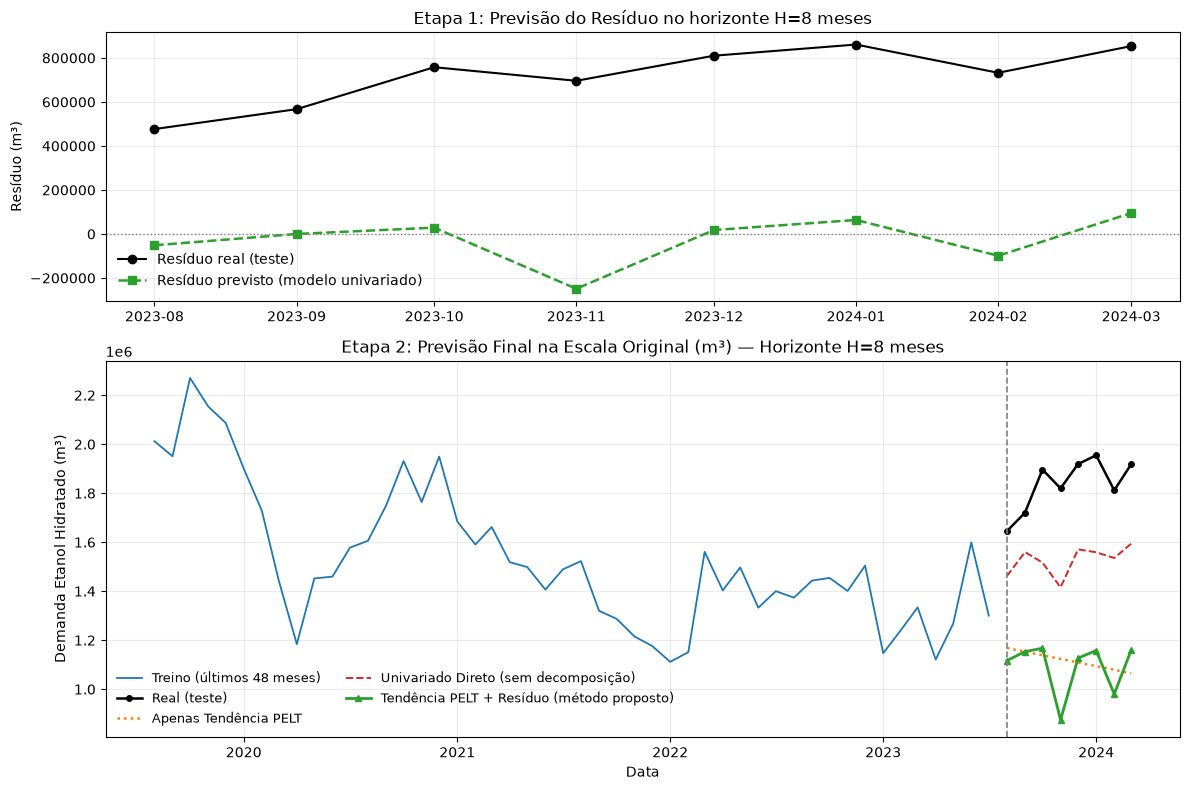

In [16]:
datas_test = datas[n_tr:]
janela_plot = 48  # últimos 4 anos de treino para contexto visual
unidade_res = "log" if is_log else "m³"

fig, axes = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={'height_ratios': [1, 1.4]})

# Gráfico 1: Resíduo real vs previsto no horizonte H
axes[0].plot(datas_test, residuo_test, 'o-', color='black', lw=1.5, label='Resíduo real (teste)')
axes[0].plot(datas_test, residuo_pred, 's--', color='tab:green', lw=1.8, label='Resíduo previsto (modelo univariado)')
axes[0].axhline(0, color='gray', ls=':', lw=1.0)
axes[0].set_title(f'Etapa 1: Previsão do Resíduo no horizonte H={H} meses')
axes[0].set_ylabel(f'Resíduo ({unidade_res})')
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)

# Gráfico 2: Reconstrução final na escala original (m³)
axes[1].plot(datas[n_tr - janela_plot : n_tr], to_m3(y_train[-janela_plot:]),
             color='tab:blue', lw=1.3, label='Treino (últimos 48 meses)')
axes[1].plot(datas_test, y_real_m3, 'o-', color='black', lw=1.8, ms=4, label='Real (teste)')
axes[1].plot(datas_test, pred_tend_m3, ':', color='tab:orange', lw=1.8, label='Apenas Tendência PELT')
axes[1].plot(datas_test, pred_direto_m3, '--', color='tab:red', lw=1.4, label='Univariado Direto (sem decomposição)')
axes[1].plot(datas_test, pred_metodo_m3, '^-', color='tab:green', lw=2.0, ms=5,
             label='Tendência PELT + Resíduo (método proposto)')
axes[1].axvline(datas_test[0], color='gray', ls='--', lw=1.2)
axes[1].set_title(f'Etapa 2: Previsão Final na Escala Original (m³) — Horizonte H={H} meses')
axes[1].set_ylabel('Demanda Etanol Hidratado (m³)')
axes[1].set_xlabel('Data')
axes[1].legend(frameon=False, ncol=2, fontsize=9)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()